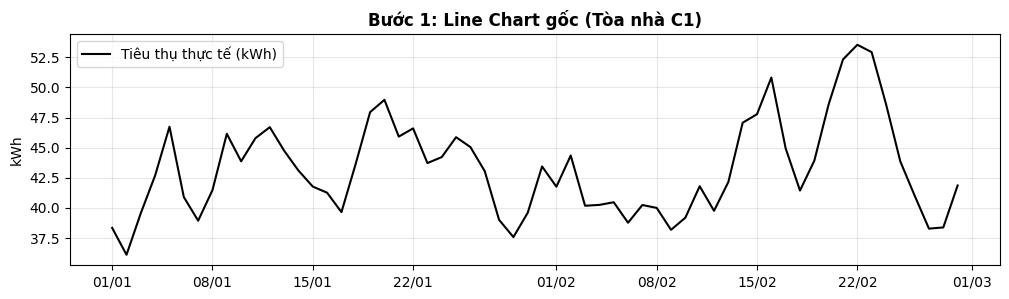

In [ ]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(dates, y, color='black', linewidth=1.5, label='Tiêu thụ thực tế (kWh)')
ax.set_title('Bước 1: Line Chart gốc (Tòa nhà C1)', fontweight='bold')
ax.set_ylabel('kWh')
ax.grid(True, alpha=0.3)

# Chú thích đặt góc trên bên trái
ax.legend(loc='upper left')

# Update x-axis

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))

plt.show()

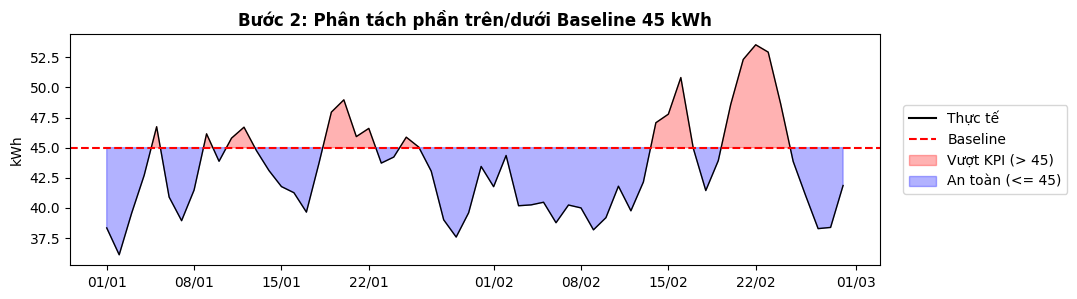

In [ ]:
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(dates, y, color='black', linewidth=1)
ax.axhline(baseline, color='red', linestyle='--', linewidth=1.5)

ax.fill_between(dates, baseline, y, where=(y > baseline), interpolate=True, color='red', alpha=0.3)
ax.fill_between(dates, baseline, y, where=(y <= baseline), interpolate=True, color='blue', alpha=0.3)

ax.set_title('Bước 2: Phân tách phần trên/dưới Baseline 45 kWh', fontweight='bold')
ax.set_ylabel('kWh')

# Tạo thủ công các đối tượng chú thích
red_patch = mpatches.Patch(color='red', alpha=0.3, label='Vượt KPI (> 45)')
blue_patch = mpatches.Patch(color='blue', alpha=0.3, label='An toàn (<= 45)')
line_real = mlines.Line2D([], [], color='black', label='Thực tế')
line_base = mlines.Line2D([], [], color='red', linestyle='--', label='Baseline')

ax.legend(handles=[line_real, line_base, red_patch, blue_patch],
          loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.subplots_adjust(right=0.8) # Bóp không gian nhường chỗ cho legend

# Update x-axis

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))

plt.show()

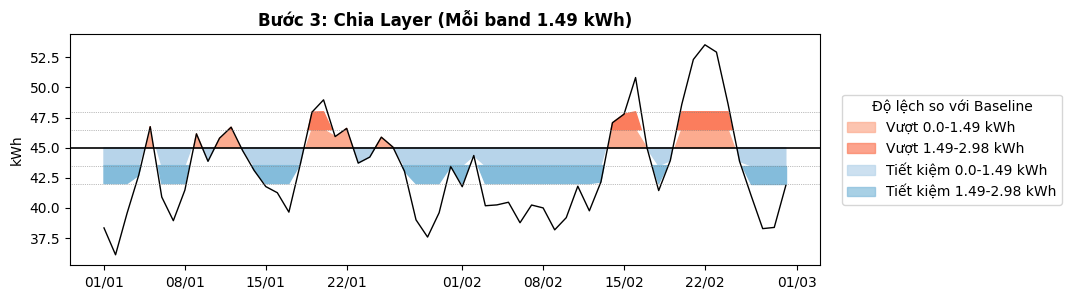

In [ ]:
import matplotlib.patches as mpatches
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(dates, y, color='black', linewidth=1)
ax.axhline(baseline, color='black', linewidth=1.2)

for i in range(max_bands):
    lower = baseline + i * band_size
    upper = baseline + (i + 1) * band_size
    ax.axhline(upper, color='gray', linestyle=':', linewidth=0.5)
    ax.fill_between(dates, lower, np.minimum(y, upper), where=(y > lower), interpolate=True, color=colors_pos[i])

for i in range(min_bands):
    upper = baseline - i * band_size
    lower = baseline - (i + 1) * band_size
    ax.axhline(lower, color='gray', linestyle=':', linewidth=0.5)
    ax.fill_between(dates, upper, np.maximum(y, lower), where=(y < upper), interpolate=True, color=colors_neg[i])

ax.set_title(f'Bước 3: Chia Layer (Mỗi band {band_size} kWh)', fontweight='bold')
ax.set_ylabel('kWh')

# Define band_legend_patches before using it
band_legend_patches = []

# Patches for positive bands (above baseline)
for i in range(max_bands):
    lower_bound = i * band_size
    upper_bound = (i + 1) * band_size
    band_legend_patches.append(mpatches.Patch(color=colors_pos[i], alpha=0.7,
                                              label=f'Vượt {lower_bound}-{upper_bound} kWh'))

# Patches for negative bands (below baseline)
for i in range(min_bands):
    lower_bound = i * band_size
    upper_bound = (i + 1) * band_size
    band_legend_patches.append(mpatches.Patch(color=colors_neg[i], alpha=0.7,
                                              label=f'Tiết kiệm {lower_bound}-{upper_bound} kWh'))

ax.legend(handles=band_legend_patches, loc='center left', bbox_to_anchor=(1.02, 0.5), title="Độ lệch so với Baseline")
plt.subplots_adjust(right=0.75)

# Update x-axis

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))

plt.show()

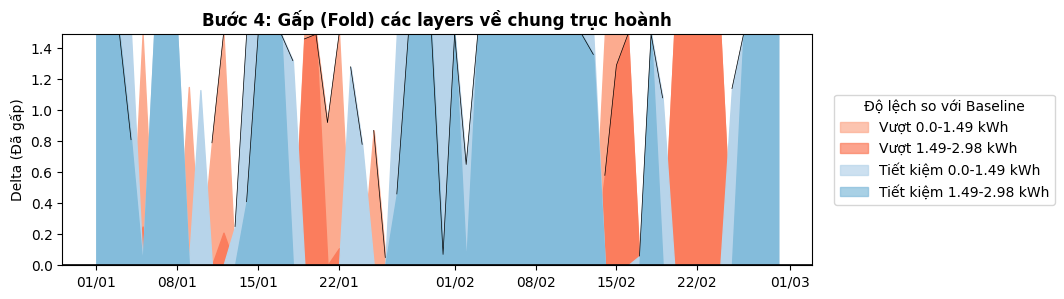

In [ ]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 3))
ax.axhline(0, color='black', linewidth=1.2)

for i in range(max_bands):
    lower = baseline + i * band_size
    y_band = np.clip(y - lower, 0, band_size)
    ax.fill_between(dates, 0, y_band, color=colors_pos[i])
    y_line = np.where(y_band > 0, y_band, np.nan)
    ax.plot(dates, y_line, color='black', linewidth=0.5)

for i in range(min_bands):
    upper = baseline - i * band_size
    y_band = np.clip(upper - y, 0, band_size)
    ax.fill_between(dates, 0, y_band, color=colors_neg[i])
    y_line = np.where(y_band > 0, y_band, np.nan)
    ax.plot(dates, y_line, color='black', linewidth=0.5)

ax.set_title('Bước 4: Gấp (Fold) các layers về chung trục hoành', fontweight='bold')
ax.set_ylabel('Delta (Đã gấp)')
ax.set_ylim(0, band_size)

ax.legend(handles=band_legend_patches, loc='center left', bbox_to_anchor=(1.02, 0.5), title="Độ lệch so với Baseline")
plt.subplots_adjust(right=0.75)

# Update x-axis

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))

plt.show()

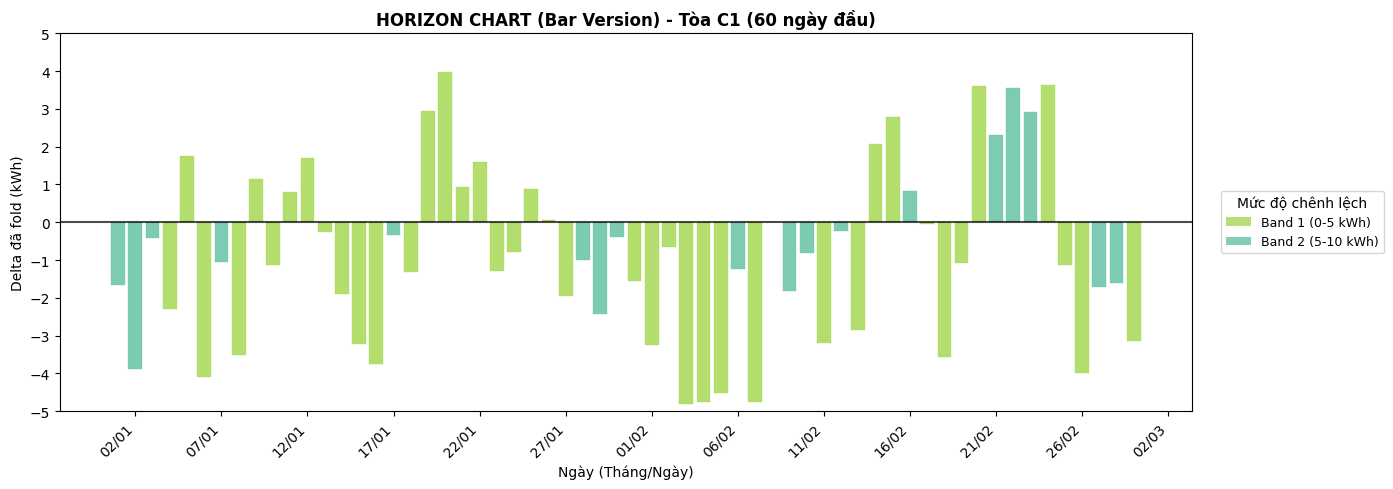

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from matplotlib.patches import Patch

# Đọc dữ liệu
df = pd.read_csv('energy_consumption_dataset.csv')
df['date'] = pd.to_datetime(df['date'])

# Lấy 60 ngày đầu tiên
df_60 = df.head(60).copy()

# Thiết lập baseline
baseline = 45
df_60['delta_C1'] = df_60['kwh_C1'] - baseline

# ============================================
# HÀM FOLD
# ============================================
def fold_delta(delta, band_size=5):
    abs_delta = abs(delta)
    band_number = int(abs_delta // band_size)
    folded_value = abs_delta - (band_number * band_size)

    if delta < 0:
        return -folded_value, band_number
    else:
        return folded_value, band_number

# Áp dụng fold
df_60['folded_value'], df_60['band_number'] = zip(*df_60['delta_C1'].apply(
    lambda x: fold_delta(x, 5)
))

max_band = df_60['band_number'].max()
band_size = 5

# ============================================
# MÀU SẮC CHO CÁC BAND
# ============================================
colors = ['#a6d854', '#66c2a5', '#fc8d62', '#d53e4f', '#9e0142']

# ============================================
# KHỞI TẠO ĐỒ THỊ (Chỉ giữ lại 1 trục ax)
# ============================================
fig, ax = plt.subplots(figsize=(14, 5))

# --- VẼ BAR ---
for band in range(max_band + 1):
    band_data = df_60[df_60['band_number'] == band]

    if not band_data.empty:
        above = band_data[band_data['delta_C1'] >= 0]
        below = band_data[band_data['delta_C1'] < 0]

        if not above.empty:
            ax.bar(above['date'], above['folded_value'],
                   color=colors[band], alpha=0.85, width=0.8,
                   edgecolor=colors[band], linewidth=0.3)

        if not below.empty:
            ax.bar(below['date'], below['folded_value'],
                   color=colors[band], alpha=0.85, width=0.8,
                   edgecolor=colors[band], linewidth=0.3)

# Cấu hình trục và hiển thị
ax.axhline(y=0, color='black', linewidth=1.5, alpha=0.7)
ax.set_ylim(-band_size, band_size)
ax.set_yticks(np.arange(-band_size, band_size + 1, 1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

# Tạo danh sách Legend cho các Band màu
legend_elements = []
for i in range(min(4, max_band + 1)):
    legend_elements.append(
        Patch(facecolor=colors[i], alpha=0.8,
              label=f'Band {i+1} ({i*band_size}-{(i+1)*band_size} kWh)')
    )

# Hiển thị Legend cho ax
ax.legend(handles=legend_elements, loc='center left',
          bbox_to_anchor=(1.02, 0.5),
          title="Mức độ chênh lệch",
          title_fontsize=10, fontsize=9)

ax.set_title('HORIZON CHART (Bar Version) - Tòa C1 (60 ngày đầu)',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Delta đã fold (kWh)', fontsize=10)
ax.set_xlabel('Ngày (Tháng/Ngày)', fontsize=10)

plt.subplots_adjust(right=0.8)
plt.tight_layout()
plt.show()



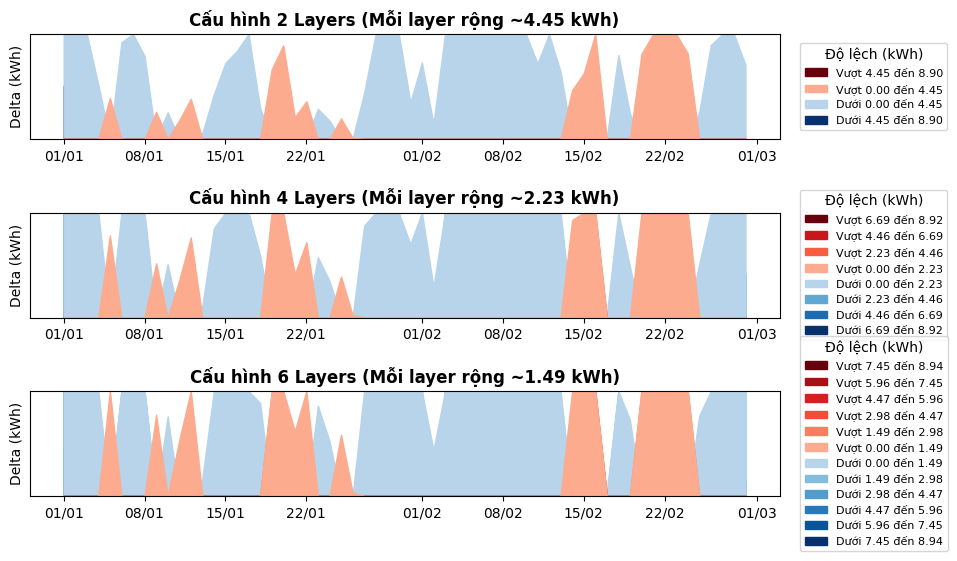

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.dates as mdates

# 1. Đọc dữ liệu
df = pd.read_csv('energy_consumption_dataset.csv')
df['date'] = pd.to_datetime(df['date'])
subset = df.head(60).copy()
dates = subset['date']
y = subset['kwh_C1']
baseline = 45

# Tính độ lệch lớn nhất (Max deviation) để chia đều cho các layer
max_dev = max(y.max() - baseline, baseline - y.min()) # Rơi vào khoảng 8.89 kWh

# 2. Cấu hình vẽ 3 biểu đồ
layer_configs = [2, 4, 6]
fig, axes = plt.subplots(len(layer_configs), 1, figsize=(12, 6))
plt.subplots_adjust(hspace=0.7, right=0.75)

for idx, num_layers in enumerate(layer_configs):
    ax = axes[idx]

    # Tính kích thước của mỗi dải băng (Band size)
    band_size = np.ceil((max_dev / num_layers) * 100) / 100

    # Tạo dải màu tự động từ nhạt đến đậm
    cmap_pos = plt.get_cmap('Reds')
    cmap_neg = plt.get_cmap('Blues')

    colors_pos = [cmap_pos(0.3 + 0.7 * (i / (num_layers - 1)) if num_layers > 1 else 0.5) for i in range(num_layers)]
    colors_neg = [cmap_neg(0.3 + 0.7 * (i / (num_layers - 1)) if num_layers > 1 else 0.5) for i in range(num_layers)]

    # Vẽ Horizon Chart
    for i in range(num_layers)[::-1]:
        upper = baseline - i * band_size
        y_band = np.clip(upper - y, 0, band_size)
        ax.fill_between(dates, 0, y_band, color=colors_neg[i])

    for i in range(num_layers)[::-1]:
        lower = baseline + i * band_size
        y_band = np.clip(y - lower, 0, band_size)
        ax.fill_between(dates, 0, y_band, color=colors_pos[i])

    ax.set_title(f'Cấu hình {num_layers} Layers (Mỗi layer rộng ~{band_size:.2f} kWh)', fontweight='bold')
    ax.set_yticks([])
    ax.set_ylim(0, band_size)

    # Set y-axis label for each subplot
    ax.set_ylabel('Delta (kWh)')

    # Format x-axis ticks to show only day/month
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))

    # Tạo Legend
    legend_patches = []
    for i in range(num_layers)[::-1]:
        label = f"Vượt {i*band_size:.2f} đến {(i+1)*band_size:.2f}"
        legend_patches.append(mpatches.Patch(color=colors_pos[i], label=label))
    for i in range(num_layers):
        label = f"Dưới {i*band_size:.2f} đến {(i+1)*band_size:.2f}"
        legend_patches.append(mpatches.Patch(color=colors_neg[i], label=label))

    ax.legend(handles=legend_patches, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8, title='Độ lệch (kWh)')

plt.show()

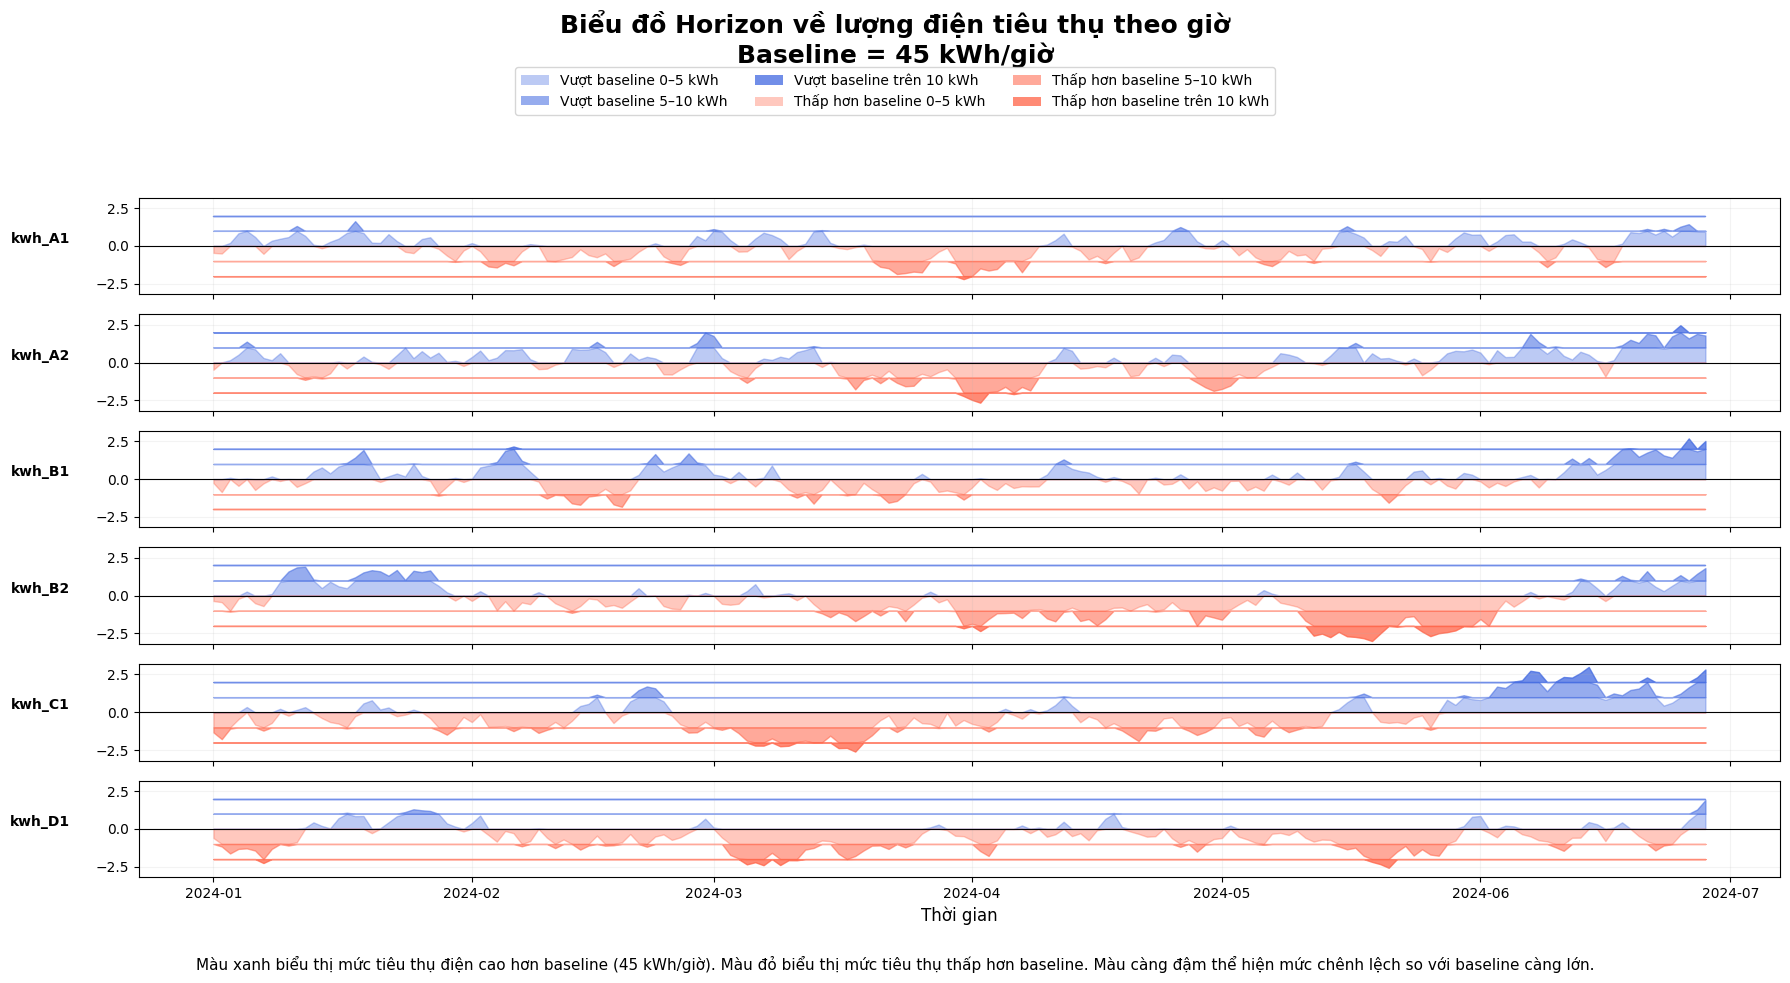

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ======================================================
# Đọc dữ liệu
# ======================================================

df = pd.read_csv("energy_consumption_dataset.csv")

# Chuyển cột ngày sang kiểu datetime
df["date"] = pd.to_datetime(df["date"])

# Danh sách 6 chuỗi thời gian
series = [
    "kwh_A1",
    "kwh_A2",
    "kwh_B1",
    "kwh_B2",
    "kwh_C1",
    "kwh_D1"
]

# ======================================================
# Thiết lập Horizon Chart
# ======================================================

baseline = 45          # Baseline KPI
bands = 3              # Số dải màu
band_height = 5        # Mỗi dải tương ứng 5 kWh

# ======================================================
# Tạo biểu đồ
# ======================================================

fig, axes = plt.subplots(
    len(series),
    1,
    figsize=(18, 10),
    sharex=True
)

fig.suptitle(
    "Biểu đồ Horizon về lượng điện tiêu thụ theo giờ\nBaseline = 45 kWh/giờ",
    fontsize=18,
    fontweight="bold"
)

# ======================================================
# Vẽ Horizon Chart
# ======================================================

for ax, col in zip(axes, series):

    x = df["date"]

    # Sai lệch so với baseline
    delta = df[col] - baseline

    # ----------- Phần vượt baseline (màu xanh) ----------
    for i in range(bands):

        lower = i * band_height

        band = np.clip(
            delta - lower,
            0,
            band_height
        )

        ax.fill_between(
            x,
            i,
            i + band / band_height,
            color="royalblue",
            alpha=0.35 + i * 0.2
        )

    # ----------- Phần thấp hơn baseline (màu đỏ) ----------
    for i in range(bands):

        lower = i * band_height

        band = np.clip(
            -delta - lower,
            0,
            band_height
        )

        ax.fill_between(
            x,
            -i,
            -(i + band / band_height),
            color="tomato",
            alpha=0.35 + i * 0.2
        )

    # Đường baseline
    ax.axhline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_ylim(-3.2, 3.2)

    ax.set_ylabel(
        col,
        rotation=0,
        labelpad=40,
        fontsize=10,
        fontweight="bold"
    )

    ax.grid(alpha=0.15)

# ======================================================
# Chú thích (Legend)
# ======================================================

legend_elements = [

    Patch(
        facecolor="royalblue",
        alpha=0.35,
        label="Vượt baseline 0–5 kWh"
    ),

    Patch(
        facecolor="royalblue",
        alpha=0.55,
        label="Vượt baseline 5–10 kWh"
    ),

    Patch(
        facecolor="royalblue",
        alpha=0.75,
        label="Vượt baseline trên 10 kWh"
    ),

    Patch(
        facecolor="tomato",
        alpha=0.35,
        label="Thấp hơn baseline 0–5 kWh"
    ),

    Patch(
        facecolor="tomato",
        alpha=0.55,
        label="Thấp hơn baseline 5–10 kWh"
    ),

    Patch(
        facecolor="tomato",
        alpha=0.75,
        label="Thấp hơn baseline trên 10 kWh"
    )

]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    fontsize=10,
    frameon=True
)

# ======================================================
# Nhãn trục
# ======================================================

axes[-1].set_xlabel(
    "Thời gian",
    fontsize=12
)

# ======================================================
# Ghi chú
# ======================================================

fig.text(
    0.5,
    0.02,
    "Màu xanh biểu thị mức tiêu thụ điện cao hơn baseline (45 kWh/giờ). "
    "Màu đỏ biểu thị mức tiêu thụ thấp hơn baseline. "
    "Màu càng đậm thể hiện mức chênh lệch so với baseline càng lớn.",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.05, 1, 0.88])

plt.show()